# Sampling Distributions

This notebook accompanies [Sampling Distributions](../../notes/sampling_and_sampling_distributions/sampling_distributions.md). A statistic is a random variable; its distribution over repeated samples is its sampling distribution. We build sampling distributions exactly (by enumeration) and by simulation.

## An exact sampling distribution

Population $\{1,2,3\}$ with equal probabilities, samples of size $n=2$ drawn with replacement. There are only 9 equally likely samples, so we can list the distribution of $\bar X$ exactly.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

rng = np.random.default_rng(42)

import itertools
from collections import Counter

pop = np.array([1, 2, 3])
means = [np.mean(s) for s in itertools.product(pop, repeat=2)]
dist = Counter(means)
for value in sorted(dist):
    print(f"P(xbar = {value}) = {dist[value]}/9")

m_arr = np.array(means)
print("E[xbar] =", m_arr.mean(), " mu =", pop.mean())
print("Var(xbar) =", round(m_arr.var(), 4), " sigma^2/n =", round(pop.var() / 2, 4))

P(xbar = 1.0) = 1/9
P(xbar = 1.5) = 2/9
P(xbar = 2.0) = 3/9
P(xbar = 2.5) = 2/9
P(xbar = 3.0) = 1/9
E[xbar] = 2.0  mu = 2.0
Var(xbar) = 0.3333  sigma^2/n = 0.3333


## Without replacement: the finite population correction

Drawing $n=2$ from $\{1,2,3,4\}$ without replacement gives 6 samples. The variance of the mean is $\frac{\sigma^2}{n}\frac{N-n}{N-1}$.

In [2]:
pop4 = np.array([1, 2, 3, 4])
means_wo = np.array([np.mean(s) for s in itertools.combinations(pop4, 2)])
N, n = 4, 2
print("Means:", means_wo)
print("Var(xbar) enumerated :", round(means_wo.var(), 4))
print("sigma^2/n            :", round(pop4.var() / n, 4))
print("with FPC             :", round(pop4.var() / n * (N - n) / (N - 1), 4))

Means: [1.5 2.  2.5 2.5 3.  3.5]
Var(xbar) enumerated : 0.4167
sigma^2/n            : 0.625
with FPC             : 0.4167


## Simulation: the sampling distribution of the mean

For a skewed (exponential, mean 2) population, we draw many samples of size $n$ and look at the distribution of $\bar X$. Its mean stays at $\mu$ and its standard deviation falls like $\sigma/\sqrt n$.

n=  5  mean of xbar=2.007  SE sim=0.904  sigma/sqrt n=0.894  skew=0.90
n= 30  mean of xbar=1.996  SE sim=0.361  sigma/sqrt n=0.365  skew=0.34
n=100  mean of xbar=2.000  SE sim=0.199  sigma/sqrt n=0.200  skew=0.20


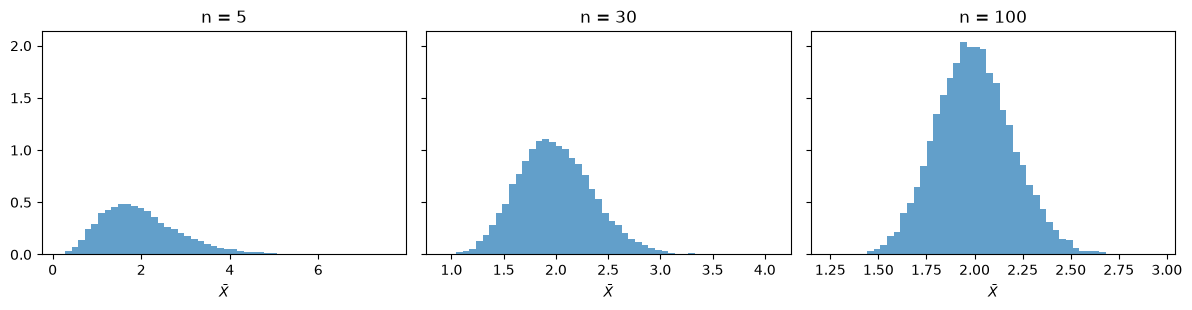

In [3]:
reps = 20_000
fig, axes = plt.subplots(1, 3, figsize=(12, 3.2), sharey=True)
for ax, n in zip(axes, (5, 30, 100)):
    xbar = rng.exponential(2.0, size=(reps, n)).mean(axis=1)
    print(f"n={n:3d}  mean of xbar={xbar.mean():.3f}  SE sim={xbar.std(ddof=1):.3f}  sigma/sqrt n={2/np.sqrt(n):.3f}  skew={stats.skew(xbar):.2f}")
    ax.hist(xbar, bins=50, density=True, alpha=0.7)
    ax.set_title(f"n = {n}"); ax.set_xlabel(r"$\bar{X}$")
plt.tight_layout(); plt.show()

## Bias versus variance of estimators

The variance estimator with divisor $n$ is biased downward: $E[\hat\sigma^2]=\frac{n-1}{n}\sigma^2$. Dividing by $n-1$ removes the bias. For normal data with $\sigma^2=25$ and $n=10$:

In [4]:
samples = rng.normal(0, 5, size=(100_000, 10))
v_n = samples.var(axis=1, ddof=0)
v_n1 = samples.var(axis=1, ddof=1)
print("E[divisor n]   ~", round(v_n.mean(), 3), "(theory 22.5)  bias ~", round(v_n.mean() - 25, 3))
print("E[divisor n-1] ~", round(v_n1.mean(), 3), "(theory 25)")
print("MSE divisor n  :", round(np.mean((v_n - 25) ** 2), 2))
print("MSE divisor n-1:", round(np.mean((v_n1 - 25) ** 2), 2), "(unbiased, yet larger MSE)")

E[divisor n]   ~ 22.457 (theory 22.5)  bias ~ -2.543
E[divisor n-1] ~ 24.952 (theory 25)
MSE divisor n  : 118.18
MSE divisor n-1: 137.91 (unbiased, yet larger MSE)


## Different statistics, different standard errors

The sampling distribution depends on the statistic. For normal data the sample median is less precise than the sample mean: $SE(\text{median})\approx1.253\,\sigma/\sqrt n$.

In [5]:
n = 50
data = rng.normal(0, 1, size=(20_000, n))
se_mean = data.mean(axis=1).std(ddof=1)
se_median = np.median(data, axis=1).std(ddof=1)
print(f"SE(mean)   = {se_mean:.4f}  (theory {1/np.sqrt(n):.4f})")
print(f"SE(median) = {se_median:.4f}  (theory ~{1.2533/np.sqrt(n):.4f})")

SE(mean)   = 0.1416  (theory 0.1414)
SE(median) = 0.1759  (theory ~0.1772)


## Sampling distribution of $S^2$ under normality

For normal samples, $(n-1)S^2/\sigma^2\sim\chi^2_{n-1}$. With $n=11$ and $\sigma^2=4$ this gives $\operatorname{Var}(S^2)=2\sigma^4/(n-1)=3.2$ and $P(S^2>6)=P(\chi^2_{10}>15)$.

In [6]:
s2 = rng.normal(0, 2, size=(100_000, 11)).var(axis=1, ddof=1)
print("E[S^2]   ~", round(s2.mean(), 3), "(4)")
print("Var(S^2) ~", round(s2.var(ddof=1), 3), "(3.2)")
print("P(S^2>6) ~", round((s2 > 6).mean(), 4), " chi-square:", round(stats.chi2.sf(15, 10), 4))

E[S^2]   ~ 4.004 (4)
Var(S^2) ~ 3.197 (3.2)
P(S^2>6) ~ 0.1314  chi-square: 0.1321
